#### Prediction of Yearly Amount Spent on Ecommerce Customners

In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [2]:
%matplotlib inline

In [3]:
df_ecom = pd.read_csv(r"C:\Users\THATO   TY\OneDrive\Data Science and Machine Learning Projects\Linear Regression\Ecommerce Customers.csv")

In [4]:
df_ecom.head()

,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\nCobbborough, D...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\nPort Jason, OH 22070-1220",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\nPort Jacobville, PR 3...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


In [5]:
df_ecom.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    str    
 1   Address               500 non-null    str    
 2   Avatar                500 non-null    str    
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), str(3)
memory usage: 31.4 KB


In [6]:
df_ecom.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Avg. Session Length,500.0,33.053194,0.992563,29.532429,32.341822,33.082008,33.711985,36.139662
Time on App,500.0,12.052488,0.994216,8.508152,11.388153,11.983231,12.753850,15.126994
Time on Website,500.0,37.060445,1.010489,33.913847,36.349257,37.069367,37.716432,40.005182
Length of Membership,500.0,3.533462,0.999278,0.269901,2.930450,3.533975,4.126502,6.922689
Yearly Amount Spent,500.0,499.314038,79.314782,256.670582,445.038277,498.887875,549.313828,765.518462


##### 2. Exploratory Data Analysis

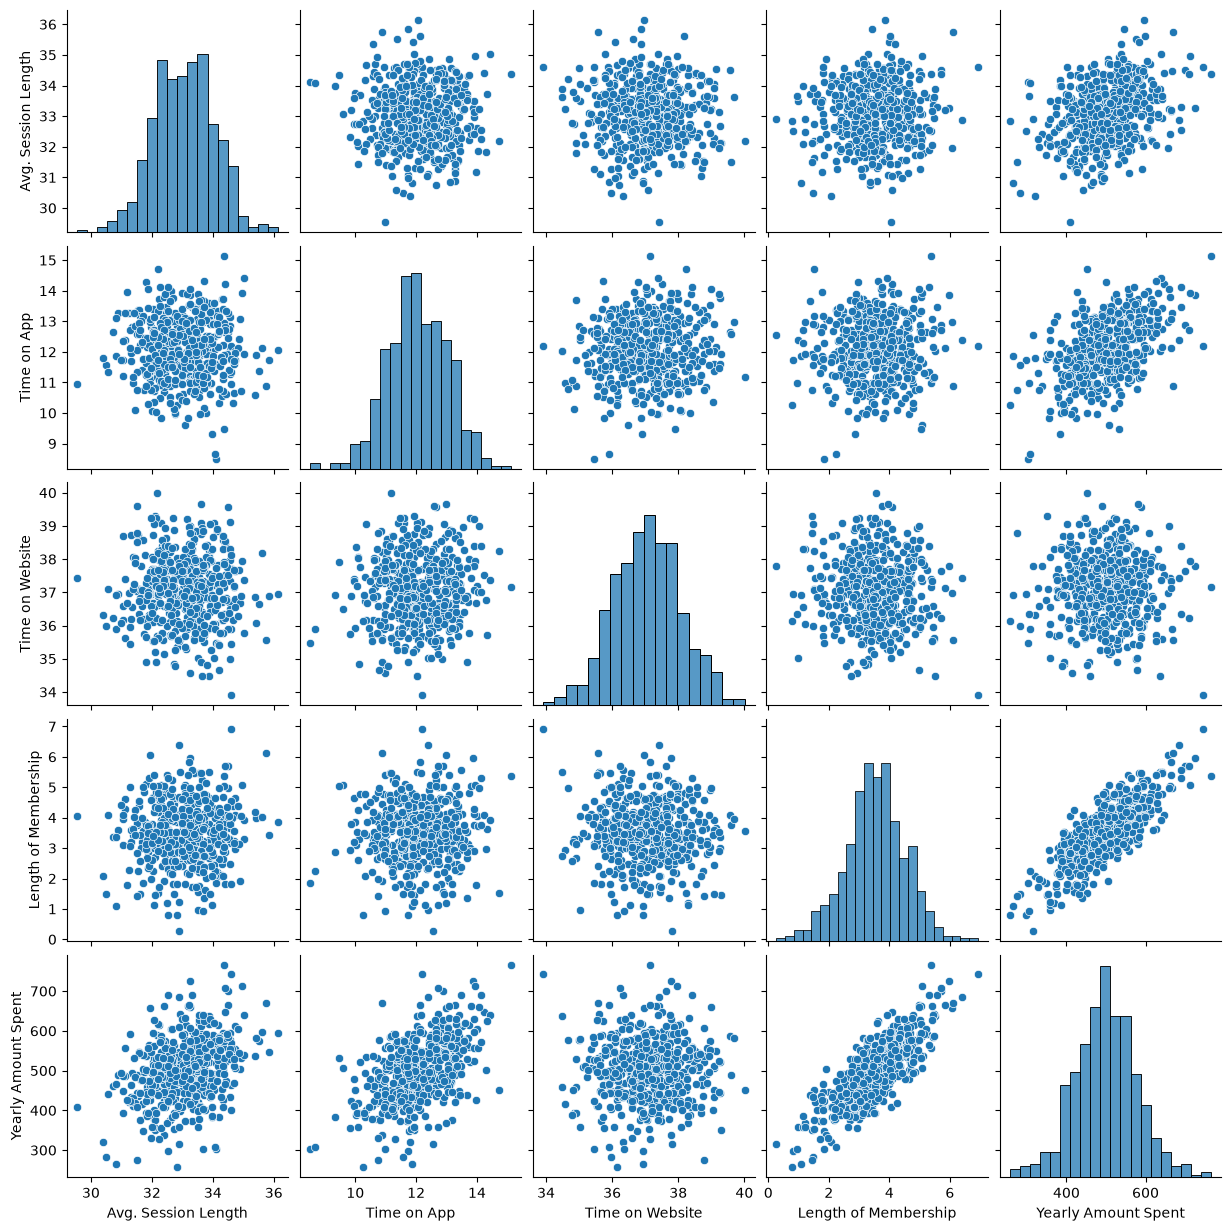

In [7]:
### Pairwise plots
sns.pairplot(df_ecom)

In [8]:
df_ecom.select_dtypes(include = 'number').corr()

,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
Avg. Session Length,1.000000,-0.027826,-0.034987,0.060247,0.355088
Time on App,-0.027826,1.000000,0.082388,0.029143,0.499328
Time on Website,-0.034987,0.082388,1.000000,-0.047582,-0.002641
Length of Membership,0.060247,0.029143,-0.047582,1.000000,0.809084
Yearly Amount Spent,0.355088,0.499328,-0.002641,0.809084,1.000000


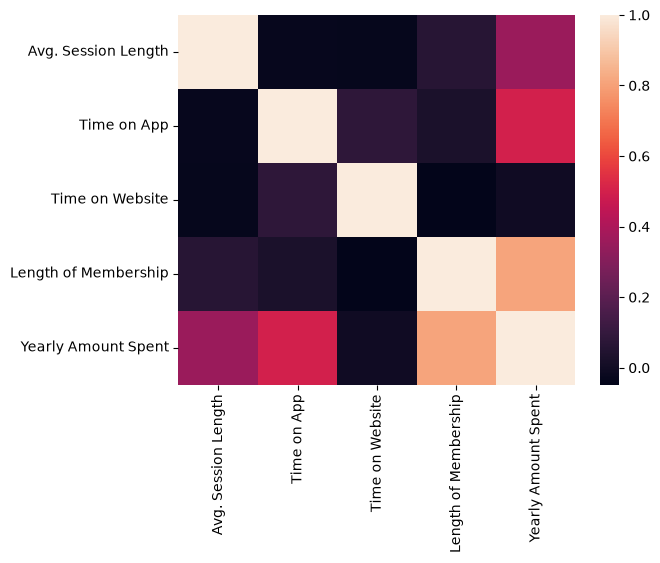

In [10]:
sns.heatmap(df_ecom.select_dtypes(include = 'number').corr())
plt.show()

Notice that the Length of Membership and the target(Yearly Amount Spent) are highly positively correlated.

#### 3. Missing values and cleaning the data where neccessary.

In [13]:
df_ecom.isnull().head()

,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False


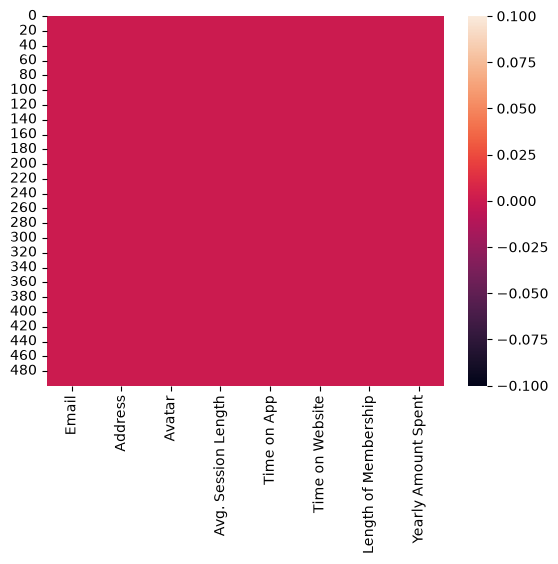

In [15]:
sns.heatmap(df_ecom.isnull())
plt.show()

In [16]:
df_ecom.isnull().sum()

Email                   0
Address                 0
Avatar                  0
Avg. Session Length     0
Time on App             0
Time on Website         0
Length of Membership    0
Yearly Amount Spent     0
dtype: int64

So the data shows no missing values anywhere.

#### 4. Splitting the Data

In [70]:
X = df_ecom.drop(['Email','Address','Avatar','Yearly Amount Spent'],axis=1)
y = df_ecom['Yearly Amount Spent']

In [71]:
from sklearn.model_selection import train_test_split 

In [72]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=42)

#### 5. Training the Model
##### 5.1. Using the unscaled dataset.

In [73]:
from sklearn.linear_model import LinearRegression

In [74]:
lm_1 = LinearRegression()
lm_1.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[25.72,38.6 , 0.46,61.67]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['Avg. Session Length','Time on App','Time on Website', 'Length of Membership']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1051
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


In [75]:
Coefficient_Table_1 = pd.concat([pd.DataFrame({'Variable':X_train.columns,'Coefficient':lm_1.coef_}),pd.DataFrame({'Variable':['Intercept'],'Coefficient':lm_1.intercept_})])
Coefficient_Table_1 = Coefficient_Table_1.reset_index()


In [76]:
Coefficient_Table_1 = Coefficient_Table_1.drop('index',axis=1)

In [77]:
Coefficient_Table_1

,Variable,Coefficient
0,Avg. Session Length,25.724256
1,Time on App,38.597135
2,Time on Website,0.459148
3,Length of Membership,61.674732
4,Intercept,-1050.653675


##### 5.2. Using the scaled dataset.

In [78]:
from sklearn.preprocessing import StandardScaler

In [79]:
Scaler = StandardScaler()
Scaler.fit(X_train)
X_train_scaled = Scaler.transform(X_train)
X_test_scaled = Scaler.transform(X_test)

In [80]:
X_train_scaled = pd.DataFrame(data = X_train_scaled,index = X_train.index,columns = X_train.columns)

In [82]:
X_test_scaled = pd.DataFrame(data = X_test_scaled,index = X_test.index,columns = X_test.columns)

In [53]:
lm_2 = LinearRegression()
lm_2.fit(X_train_scaled,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[-0. , 0. ,-0. ,-0. ,81.3]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,502.4
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](5,)","[26.79,19.2 ,18.62,17.73, 1.62]"


In [54]:
Coefficient_Table_2 = pd.concat([pd.DataFrame({'Variable':X_train.columns,'Coefficient':lm_2.coef_}),pd.DataFrame({'Variable':['Intercept'],'Coefficient':lm_2.intercept_})])
Coefficient_Table_2 = Coefficient_Table_2.reset_index()
Coefficient_Table_2 = Coefficient_Table_2.drop('index',axis=1)

In [55]:
Coefficient_Table_2

,Variable,Coefficient
0,Avg. Session Length,-1.508929e-14
1,Time on App,1.421085e-14
2,Time on Website,-4.884981e-15
3,Length of Membership,-8.881784e-15
4,Yearly Amount Spent,8.129676e+01
5,Intercept,5.023654e+02


#### 6. Model Estimation (Prediction)

In [57]:
test_prediction_1 = lm_1.predict(X_test)
test_prediction_2 = lm_2.predict(X_test_scaled)

In [ ]:
Prediction_Table pd.concat([X_test[['Email']]])

In [93]:
Prediction_Table = pd.DataFrame(df_ecom.iloc[X_test.index,[0,-1]])

In [95]:
Prediction_Table['Yearly Amount Spent - Prediction 1'] = test_prediction_1
Prediction_Table['Yearly Amount Spent - Prediction 2'] = test_prediction_2

In [96]:
Prediction_Table

,Email,Yearly Amount Spent,Yearly Amount Spent - Prediction 1,Yearly Amount Spent - Prediction 2
361,lauriewilson@jackson.com,401.033135,401.033135,401.033135
73,williamsjohnny@ferguson.info,534.777188,534.777188,534.777188
374,aaron89@gmail.com,418.602742,418.602742,418.602742
155,aaron11@luna.com,503.978379,503.978379,503.978379
104,jenniferking@hess.net,410.069611,410.069611,410.069611
...,...,...,...,...
266,christophermorrison@mcguire-carter.biz,554.003093,554.003093,554.003093
23,denise22@hernandez-townsend.com,519.340989,519.340989,519.340989
222,sanchezkara@hotmail.com,502.409785,502.409785,502.409785
261,swilliams@ball-arroyo.com,514.009818,514.009818,514.009818


#### 7. Model Performance Evaluation

In [98]:
from sklearn.metrics import mean_squared_error,mean_absolute_error

In [100]:
MAE_1 = mean_absolute_error(y_test,test_prediction_1)
MSE_1 = mean_squared_error(y_test,test_prediction_1)
RMSE_1 = np.sqrt(MSE_1)

In [101]:
MAE_2 = mean_absolute_error(y_test,test_prediction_2)
MSE_2 = mean_squared_error(y_test,test_prediction_2)
RMSE_2 = np.sqrt(MSE_2)

In [102]:
pd.DataFrame({'Error Metric':['MAE','MSE','RMSE'],'Value - Model 1':[MAE_1,MSE_1,RMSE_1],'Value - Model 2':[MAE_2,MSE_2,RMSE_2]})

,Error Metric,Value - Model 1,Value - Model 2
0,MAE,3.107440e-14,3.524292e-14
1,MSE,2.369528e-27,3.295798e-27
2,RMSE,4.867780e-14,5.740904e-14


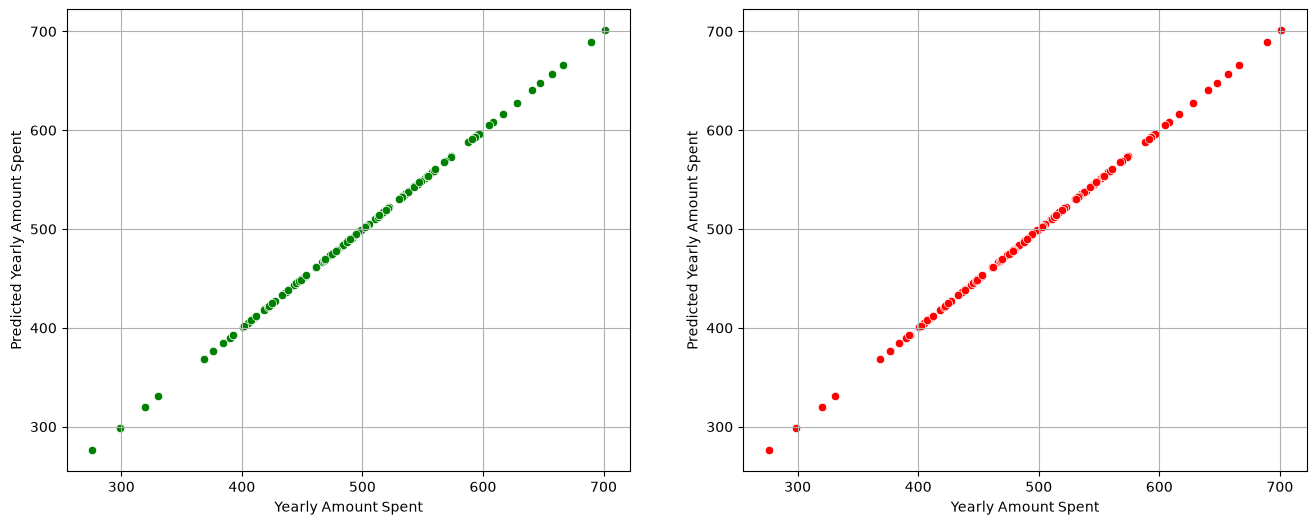

In [111]:
fig,axes = plt.subplots(1,2,figsize=(16,6))
sns.scatterplot(x = y_test, y = test_prediction_1,ax=axes[0],color='green')
sns.scatterplot(x = y_test, y = test_prediction_2,ax=axes[1],color='red')
axes[0].set_ylabel('Predicted Yearly Amount Spent')
axes[0].set_xlabel('Yearly Amount Spent')
axes[1].set_ylabel('Predicted Yearly Amount Spent')
axes[1].set_xlabel('Yearly Amount Spent')
axes[0].grid(True)
axes[1].grid(True)

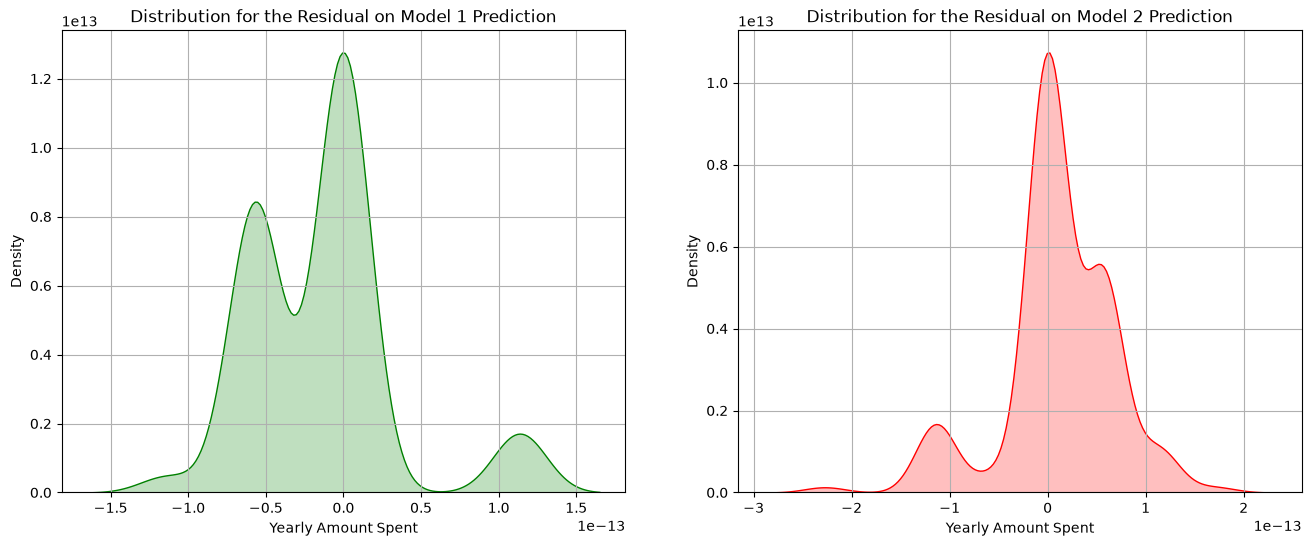

In [113]:
fig,axes = plt.subplots(1,2,figsize=(16,6))
sns.kdeplot(x = y_test-test_prediction_1,ax=axes[0],fill=True,color='green')
sns.kdeplot(x = y_test-test_prediction_2,ax=axes[1],fill=True,color='red')
axes[0].set_title('Distribution for the Residual on Model 1 Prediction')
axes[1].set_title('Distribution for the Residual on Model 2 Prediction')
axes[0].grid(True)
axes[1].grid(True)
plt.show()